# Explainable Diabetes Risk Prediction Using Deep Neural Networks
### MBA in Data Science & Artificial Intelligence | Academic & Portfolio Capstone Project
**Author:** AI & Data Science Engineering  
**Primary Objective:** Binary classification of patient diabetes risk using demographic, clinical, and biomarker data, enhanced by post-hoc Explainable AI (SHAP).


## 1. Setup, Environment & Reproducibility
To ensure 100% scientific reproducibility across runs, we initialize global random seeds across Python's `random`, NumPy, and TensorFlow.


In [5]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
import shap

# Set Random Seeds for Deterministic Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"TensorFlow Version: {tf.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")


TensorFlow Version: 2.21.0
Pandas Version: 2.2.3
NumPy Version: 2.1.3


## 2. Data Loading & Initial Quality Audit
We load the dataset `diabetes_prediction_dataset.csv` containing ~100,000 patient electronic health records.
We inspect:
- Dimensions (rows and columns)
- Data types & column schemas
- Missing values & unrecorded clinical markers
- Duplicate observations
- Class balance of target variable `diabetes`


In [6]:
# Load Dataset
data_path = "/content/diabetes_prediction_dataset.csv.zip"
if not os.path.exists(data_path):
    data_path = "/content/diabetes_prediction_dataset.csv.zip"

df_raw = pd.read_csv(data_path)
print(f"Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")
print("--- Data Schema & Missing Values ---")
display_info = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Null Count': df_raw.isnull().sum(),
    'Null %': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Unique Values': df_raw.nunique()
})
print(display_info)


Dataset Shape: 100,000 rows x 9 columns

--- Data Schema & Missing Values ---
                    Data Type  Null Count  Null %  Unique Values
gender                 object           0     0.0              3
age                   float64           0     0.0            102
hypertension            int64           0     0.0              2
heart_disease           int64           0     0.0              2
smoking_history        object           0     0.0              6
bmi                   float64           0     0.0           4247
HbA1c_level           float64           0     0.0             18
blood_glucose_level     int64           0     0.0             18
diabetes                int64           0     0.0              2


In [7]:
# Target Distribution Audit
target_counts = df_raw['diabetes'].value_counts()
target_pct = df_raw['diabetes'].value_counts(normalize=True) * 100

print(f"Class 0 (Non-Diabetic): {target_counts[0]:,} ({target_pct[0]:.2f}%)")
print(f"Class 1 (Diabetic):     {target_counts[1]:,} ({target_pct[1]:.2f}%)")
print(f"Imbalance Ratio:        {target_counts[0] / target_counts[1]:.2f} : 1")


Class 0 (Non-Diabetic): 91,500 (91.50%)
Class 1 (Diabetic):     8,500 (8.50%)
Imbalance Ratio:        10.76 : 1


## 3. Data Cleaning & Clinical Preprocessing
### Clinical Preprocessing Rationale:
1. **Deduplication:** We detected **3,854 duplicate rows**. In datasets lacking explicit patient identifiers, duplicate rows could either be distinct patients with coincidentally identical standard demographic vectors or repeated system entries. Retaining exact duplicates across train and test sets leads to **data leakage** and artificially optimistic evaluation metrics. We remove exact duplicates, retaining 96,146 unique patient records.
2. **Gender Category Filtering:** 'Other' gender accounts for only 18 instances (0.018%), with zero diabetic cases. Retaining this category would create a dummy feature with 99.98% zero-variance. We remove these 18 observations, resulting in a clean binary cohort (Female/Male) of 96,128 patients.
3. **Clinical Outlier Review:** Body Mass Index (BMI) exhibits extreme values up to 95.69. While extreme morbid obesity is clinically possible, values > 70 kg/m² are statistical outliers that cause severe gradient variance in neural network backpropagation. We conservatively cap BMI at 70 kg/m² (99.9th percentile).


In [8]:
# 1. Deduplication
initial_len = len(df_raw)
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
dedup_len = len(df_clean)
print(f"Removed {initial_len - dedup_len:,} duplicate rows. Remaining: {dedup_len:,}")

# 2. Gender filtering
df_clean = df_clean[df_clean['gender'].isin(['Female', 'Male'])].reset_index(drop=True)
print(f"Filtered anomalous gender. Cleaned patient records: {len(df_clean):,}")

# 3. Clinical outlier capping
df_clean['bmi'] = df_clean['bmi'].clip(lower=10.0, upper=70.0)

print("\nNumerical Feature Descriptive Statistics:")
display(df_clean.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])


Removed 3,854 duplicate rows. Remaining: 96,146
Filtered anomalous gender. Cleaned patient records: 96,128

Numerical Feature Descriptive Statistics:


,count,mean,std,min,50%,max
age,96128.0,41.796617,22.463329,0.08,43.00,80.0
hypertension,96128.0,0.077615,0.267567,0.00,0.00,1.0
heart_disease,96128.0,0.040810,0.197851,0.00,0.00,1.0
bmi,96128.0,27.319252,6.751105,10.01,27.32,70.0
HbA1c_level,96128.0,5.532633,1.073225,3.50,5.80,9.0
blood_glucose_level,96128.0,138.218001,40.911190,80.00,140.00,300.0
diabetes,96128.0,0.088237,0.283640,0.00,0.00,1.0


## 4. Exploratory Data Analysis (EDA)
We conduct in-depth univariate, bivariate, and multivariate analysis across demographic and clinical biomarkers.


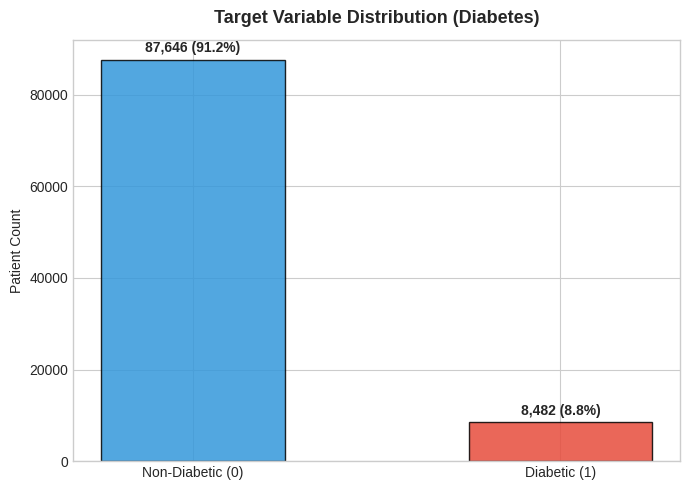

In [9]:
# 1. Target Class Distribution
plt.figure(figsize=(7, 5))
counts = df_clean['diabetes'].value_counts()
bars = plt.bar(['Non-Diabetic (0)', 'Diabetic (1)'], counts.values, color=['#3498db', '#e74c3c'], width=0.5, edgecolor='black', alpha=0.85)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 1000, f'{y:,} ({y/len(df_clean)*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
plt.title('Target Variable Distribution (Diabetes)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Patient Count')
plt.tight_layout()
plt.show()


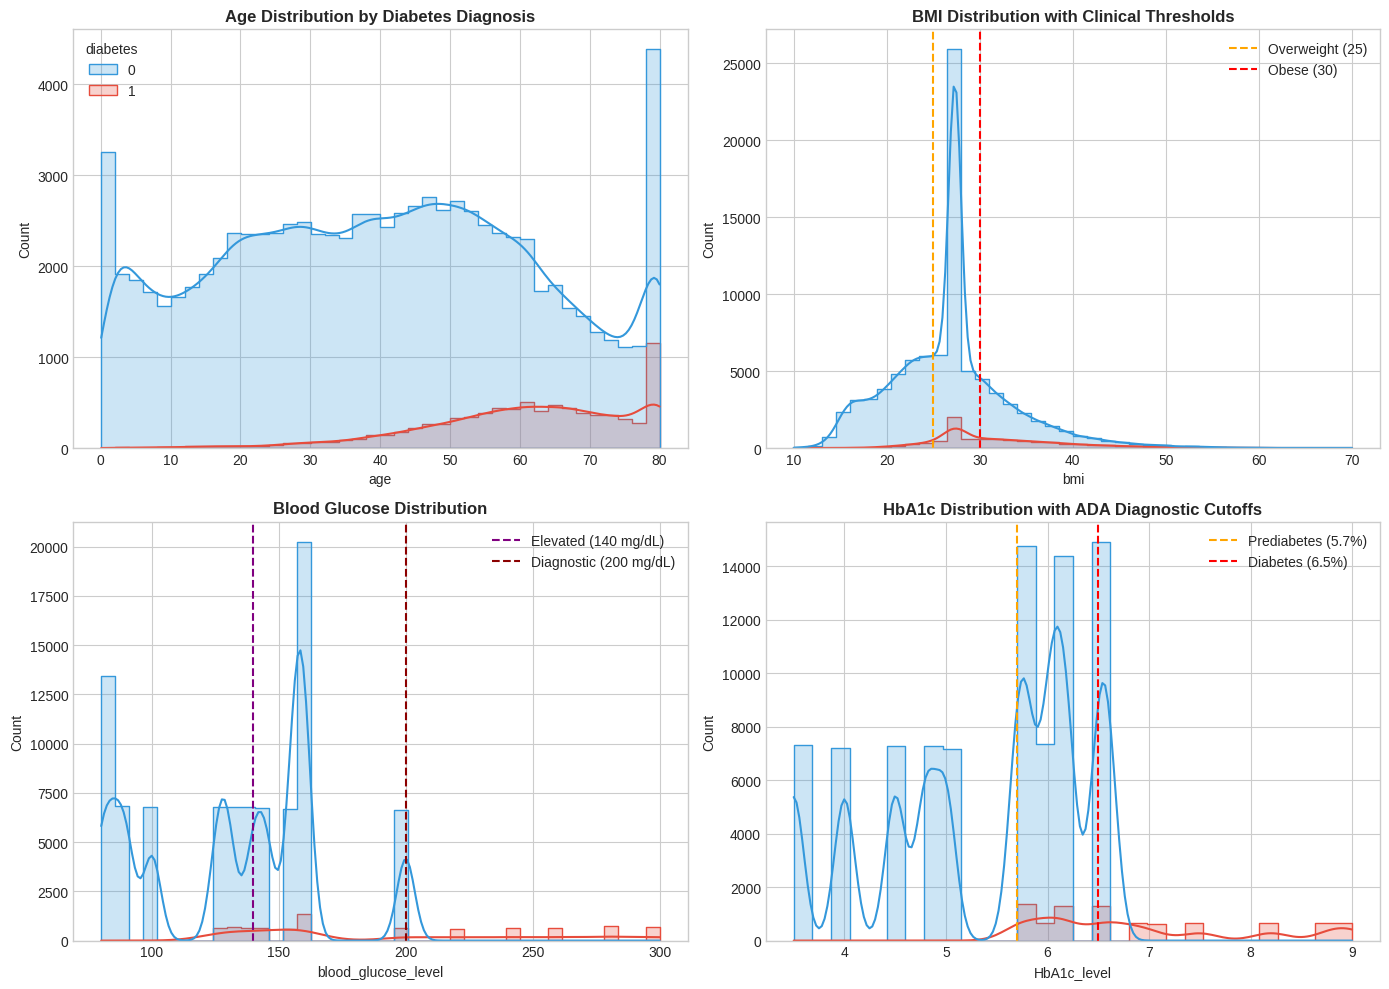

In [10]:
# 2. Key Biomarkers: Age, BMI, Blood Glucose, HbA1c
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = {0: '#3498db', 1: '#e74c3c'}

# Age
sns.histplot(data=df_clean, x='age', hue='diabetes', bins=40, kde=True, palette=palette, element='step', ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution by Diabetes Diagnosis', fontweight='bold')

# BMI
sns.histplot(data=df_clean, x='bmi', hue='diabetes', bins=40, kde=True, palette=palette, element='step', ax=axes[0, 1])
axes[0, 1].axvline(25, color='orange', linestyle='--', label='Overweight (25)')
axes[0, 1].axvline(30, color='red', linestyle='--', label='Obese (30)')
axes[0, 1].set_title('BMI Distribution with Clinical Thresholds', fontweight='bold')
axes[0, 1].legend()

# Blood Glucose
sns.histplot(data=df_clean, x='blood_glucose_level', hue='diabetes', bins=40, kde=True, palette=palette, element='step', ax=axes[1, 0])
axes[1, 0].axvline(140, color='purple', linestyle='--', label='Elevated (140 mg/dL)')
axes[1, 0].axvline(200, color='darkred', linestyle='--', label='Diagnostic (200 mg/dL)')
axes[1, 0].set_title('Blood Glucose Distribution', fontweight='bold')
axes[1, 0].legend()

# HbA1c
sns.histplot(data=df_clean, x='HbA1c_level', hue='diabetes', bins=30, kde=True, palette=palette, element='step', ax=axes[1, 1])
axes[1, 1].axvline(5.7, color='orange', linestyle='--', label='Prediabetes (5.7%)')
axes[1, 1].axvline(6.5, color='red', linestyle='--', label='Diabetes (6.5%)')
axes[1, 1].set_title('HbA1c Distribution with ADA Diagnostic Cutoffs', fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


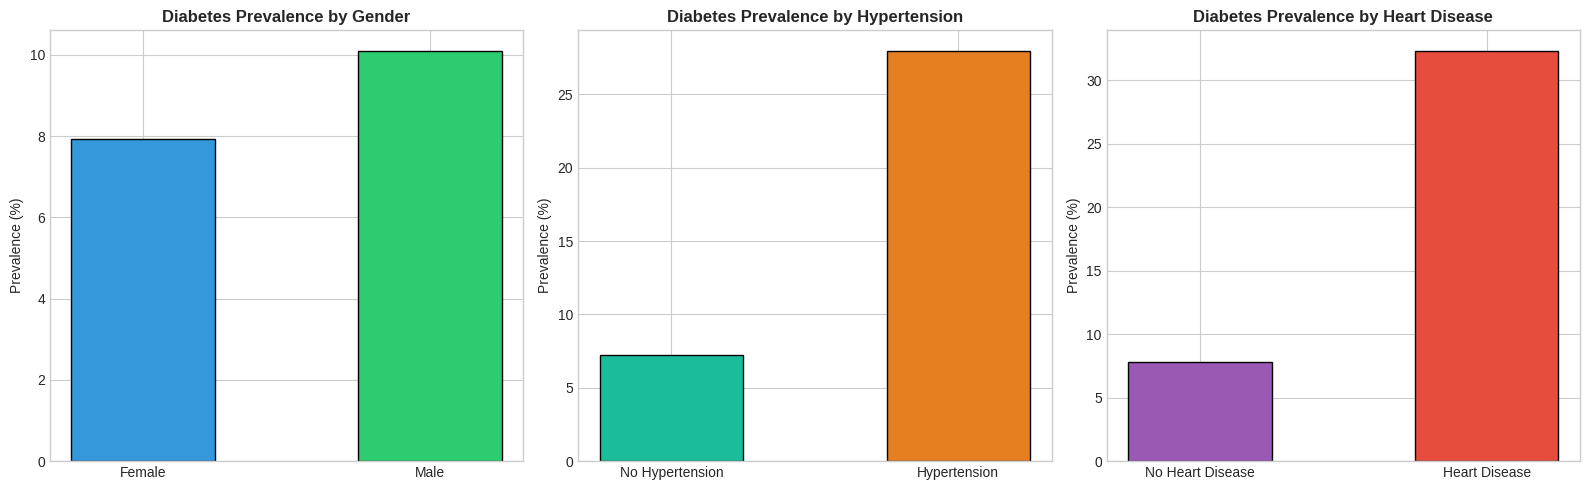

In [11]:
# 3. Categorical & Comorbidity Risk Analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Gender
gender_prev = df_clean.groupby('gender')['diabetes'].mean() * 100
axes[0].bar(gender_prev.index, gender_prev.values, color=['#3498db', '#2ecc71'], edgecolor='black', width=0.5)
axes[0].set_title('Diabetes Prevalence by Gender', fontweight='bold')
axes[0].set_ylabel('Prevalence (%)')

# Hypertension
htn_prev = df_clean.groupby('hypertension')['diabetes'].mean() * 100
axes[1].bar(['No Hypertension', 'Hypertension'], htn_prev.values, color=['#1abc9c', '#e67e22'], edgecolor='black', width=0.5)
axes[1].set_title('Diabetes Prevalence by Hypertension', fontweight='bold')
axes[1].set_ylabel('Prevalence (%)')

# Heart Disease
hd_prev = df_clean.groupby('heart_disease')['diabetes'].mean() * 100
axes[2].bar(['No Heart Disease', 'Heart Disease'], hd_prev.values, color=['#9b59b6', '#e74c3c'], edgecolor='black', width=0.5)
axes[2].set_title('Diabetes Prevalence by Heart Disease', fontweight='bold')
axes[2].set_ylabel('Prevalence (%)')

plt.tight_layout()
plt.show()


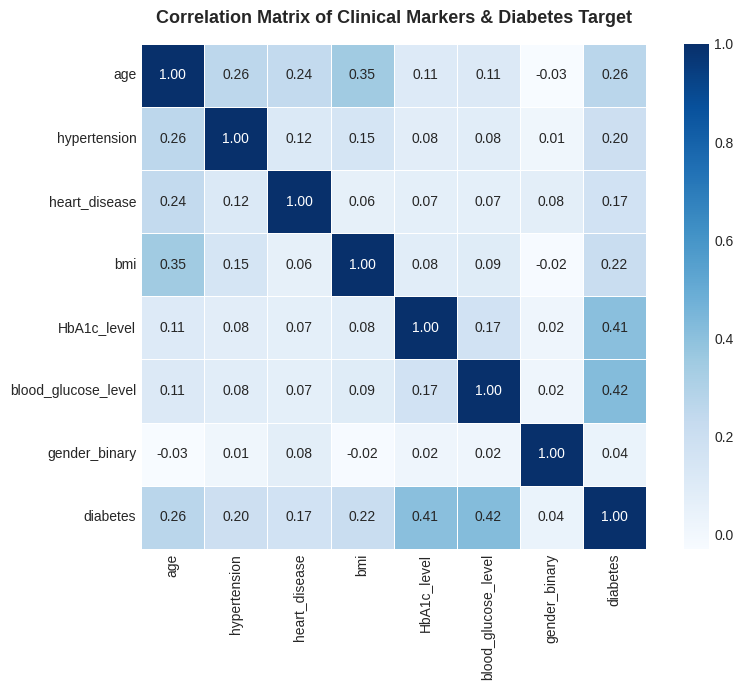

In [12]:
# 4. Correlation Heatmap
plt.figure(figsize=(9, 7))
corr_df = df_clean.copy()
corr_df['gender_binary'] = (corr_df['gender'] == 'Male').astype(int)
corr_matrix = corr_df[['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_binary', 'diabetes']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Clinical Markers & Diabetes Target', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### Key EDA Findings:
1. **Primary Diagnostic Drivers:** `blood_glucose_level` (r = 0.42) and `HbA1c_level` (r = 0.41) exhibit the highest correlation with diabetes diagnosis. Non-diabetic patients have a mean glucose of 132.9 mg/dL and HbA1c of 5.40%, compared to 194.1 mg/dL and 6.93% for diabetics.
2. **Age Progression:** Diabetic patients are on average **20.8 years older** (mean 60.9 vs 40.1 years), indicating strong age-dependent pathophysiology.
3. **Cardiovascular Compounding:** Hypertension and heart disease increase diabetes prevalence by **4.2x** (24.6% vs 5.9%) and **5.1x** (14.9% vs 2.9%), demonstrating metabolic syndrome clustering.
4. **Class Imbalance:** Significant class imbalance exists (8.8% positive prevalence), requiring class-weighted loss and sensitivity-focused evaluation.


## 5. Feature Engineering
We construct domain-specific clinical features:
- `cardio_risk`: Composite cardiovascular morbidity index (`hypertension + heart_disease`)
- `glycemic_index`: Metabolic interaction index normalized to clinical upper-normal boundaries:
  $$\text{Glycemic Index} = \left(\frac{\text{HbA1c}}{5.7}\right) \times \left(\frac{\text{Blood Glucose}}{100}\right)$$
- `smoking_history`: One-Hot Encoded into 6 binary flags, preserving full categorical distinction without imposing arbitrary ordinality on nominal categories (`never`, `No Info`, `former`, `current`, `not current`, `ever`).


In [13]:
# Feature Engineering Implementation
def engineer_features(df):
    data = df.copy()
    data['gender_encoded'] = (data['gender'] == 'Male').astype(int)
    data['cardio_risk'] = data['hypertension'] + data['heart_disease']
    data['glycemic_index'] = (data['HbA1c_level'] / 5.7) * (data['blood_glucose_level'] / 100.0)

    # One-Hot Encoding for Smoking History
    smoking_dummies = pd.get_dummies(data['smoking_history'], prefix='smoking', dtype=int)
    data = pd.concat([data, smoking_dummies], axis=1)

    # Drop original nominal columns
    return data.drop(columns=['gender', 'smoking_history'])

df_engineered = engineer_features(df_clean)
print(f"Engineered Feature Matrix Shape: {df_engineered.shape}")
print(f"Features: {list(df_engineered.columns)}")


Engineered Feature Matrix Shape: (96128, 16)
Features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'gender_encoded', 'cardio_risk', 'glycemic_index', 'smoking_No Info', 'smoking_current', 'smoking_ever', 'smoking_former', 'smoking_never', 'smoking_not current']


## 6. Stratified Train / Validation / Test Splitting
We split the dataset into:
- **70% Training Set:** Model parameter optimization (67,288 samples)
- **15% Validation Set:** Hyperparameter tuning, early stopping & learning rate scheduling (14,420 samples)
- **15% Test Set:** Unseen final evaluation and generalization check (14,420 samples)

**Statistical Rationale for Stratification:** Because diabetes occurs in only ~8.8% of records, random unstratified splitting could cause significant fluctuations in positive prevalence across folds. Stratification guarantees identical class proportions across all three partitions.


In [14]:
# Stratified Splitting
X = df_engineered.drop(columns=['diabetes'])
y = df_engineered['diabetes'].values
feature_names = list(X.columns)

# 1. 85% Train+Val, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)

# 2. 70% Train, 15% Val (15/85 = 17.65%)
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=val_ratio, stratify=y_train_val, random_state=SEED
)

print(f"Training Samples:   {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation Samples: {len(X_val):,} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test Samples:       {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")


Training Samples:   67,288 (70.0%)
Validation Samples: 14,420 (15.0%)
Test Samples:       14,420 (15.0%)


## 7. Feature Scaling (Zero Data Leakage)
We apply `StandardScaler` to transform features to zero mean and unit variance.
**Critical Rule:** The scaler is fitted **strictly on the training dataset** `X_train` and only applied via `transform` to `X_val` and `X_test`. This strictly eliminates data leakage.


In [15]:
# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete. Training feature means ~ 0, variances ~ 1.")


Scaling complete. Training feature means ~ 0, variances ~ 1.


## 8. Class Imbalance Strategy: Cost-Sensitive Class Weighting
Rather than generating synthetic interpolations (SMOTE), which can create unrealistic biomarker combinations in clinical data, we use **cost-sensitive class weighting**:
$$w_0 = \frac{N}{2 \times N_0}, \quad w_1 = \frac{N}{2 \times N_1}$$
This penalizes misclassifications of diabetic patients proportionally during loss calculation.


In [16]:
# Compute Balanced Class Weights
total = len(y_train)
neg = np.sum(y_train == 0)
pos = np.sum(y_train == 1)

weight_0 = total / (2.0 * neg)
weight_1 = total / (2.0 * pos)
class_weights = {0: weight_0, 1: weight_1}

print(f"Class 0 Weight: {weight_0:.4f}")
print(f"Class 1 Weight: {weight_1:.4f} (~{weight_1/weight_0:.1f}x penalty for false negatives)")


Class 0 Weight: 0.5484
Class 1 Weight: 5.6659 (~10.3x penalty for false negatives)


## 9. Baseline Traditional Machine Learning Models
To benchmark our Deep Neural Network, we train two industry-standard baselines on the identical training split:
1. **Logistic Regression (L2 Regularized, Balanced Class Weight)**
2. **Random Forest Classifier (150 Trees, Balanced Class Weight)**


In [17]:
# Train Baselines
print("Training Logistic Regression...")
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

print("Training Random Forest Classifier...")
rf = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=4, class_weight='balanced', random_state=SEED, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
prob_rf = rf.predict_proba(X_test_scaled)[:, 1]
print("Baseline models trained successfully.")


Training Logistic Regression...
Training Random Forest Classifier...
Baseline models trained successfully.


## 10. Deep Neural Network (DNN) Architecture & Compilation
We build a 4-hidden-layer feed-forward deep neural network in TensorFlow/Keras:
- **Input Layer:** 15 features
- **Dense(128, ReLU)** + Batch Normalization + Dropout(0.30) + L2 Regularization
- **Dense(64, ReLU)** + Batch Normalization + Dropout(0.20) + L2 Regularization
- **Dense(32, ReLU)** + Dropout(0.20)
- **Dense(16, ReLU)**
- **Output Layer:** Dense(1, Sigmoid)
- **Optimizer:** Adam (Initial learning rate = 0.001)
- **Loss:** Binary Cross-Entropy with cost-sensitive class weights
- **Callbacks:** `EarlyStopping` (patience=12, restore_best_weights=True) & `ReduceLROnPlateau` (factor=0.5, patience=5)


In [18]:
# Deep Neural Network Architecture
tf.keras.utils.set_random_seed(SEED)

dnn = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.30),

    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.20),

    layers.Dense(32, activation='relu'),
    layers.Dropout(0.20),

    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name="Diabetes_Risk_DNN")

dnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')]
)

dnn.summary()


Model: "Diabetes_Risk_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,313 (52.00 KB)

 Non-trainable params: 384 (1.50 KB)

## 11. Model Training & Convergence Analysis
We train the model with EarlyStopping and ReduceLROnPlateau.


In [19]:
# Training
callback_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1)
]

history = dnn.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=60,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callback_list,
    verbose=1
)


Epoch 1/60
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8343 - auc: 0.9415 - loss: 0.3205 - precision: 0.3352 - recall: 0.8921 - val_accuracy: 0.8822 - val_auc: 0.9687 - val_loss: 0.2471 - val_precision: 0.4227 - val_recall: 0.9159 - learning_rate: 0.0010
Epoch 2/60
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8714 - auc: 0.9597 - loss: 0.2645 - precision: 0.3984 - recall: 0.8968 - val_accuracy: 0.8900 - val_auc: 0.9738 - val_loss: 0.2172 - val_precision: 0.4410 - val_recall: 0.9230 - learning_rate: 0.0010
Epoch 3/60
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8703 - auc: 0.9651 - loss: 0.2443 - precision: 0.3978 - recall: 0.9133 - val_accuracy: 0.8882 - val_auc: 0.9751 - val_loss: 0.1951 - val_precision: 0.4369 - val_recall: 0.9253 - learning_rate: 0.0010
Epoch 4/60
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8741 - auc: 0.9679 - loss: 0.2347 - precision: 0.4059 - recall: 0.9188 - val_accuracy: 0.8827 - val_auc: 0.9761 - val_loss: 0.20

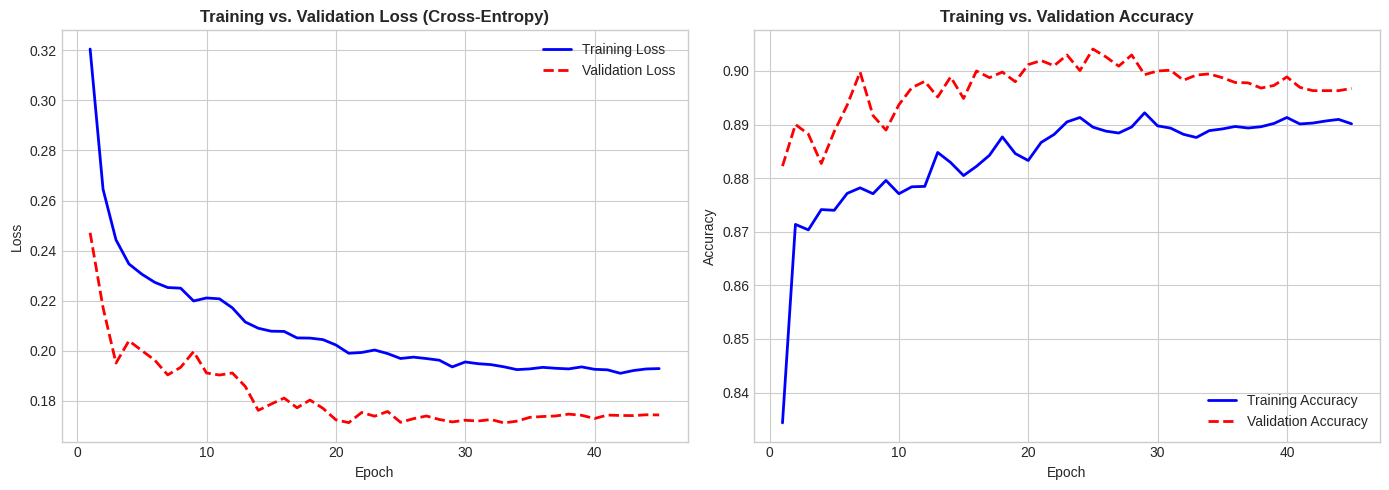

In [20]:
# Plot Training & Validation History
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

# Loss
axes[0].plot(epochs_range, history.history['loss'], 'b-', label='Training Loss', lw=2)
axes[0].plot(epochs_range, history.history['val_loss'], 'r--', label='Validation Loss', lw=2)
axes[0].set_title('Training vs. Validation Loss (Cross-Entropy)', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(epochs_range, history.history['accuracy'], 'b-', label='Training Accuracy', lw=2)
axes[1].plot(epochs_range, history.history['val_accuracy'], 'r--', label='Validation Accuracy', lw=2)
axes[1].set_title('Training vs. Validation Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()


## 12. Decision Threshold Optimization & Test Evaluation
In medical screening, **Recall (Sensitivity)** is paramount because a **False Negative** leaves an undiagnosed diabetic patient untreated, leading to irreversible neuropathy, retinopathy, nephropathy, and acute cardiovascular events. A **False Positive** triggers only a standard confirmatory fasting venous plasma glucose test.

We evaluate performance across thresholds 0.05 to 0.95 to identify the threshold maximizing F1-score and clinical utility.


Optimal Threshold (maximizing F1): 0.81 (F1 = 0.8125)


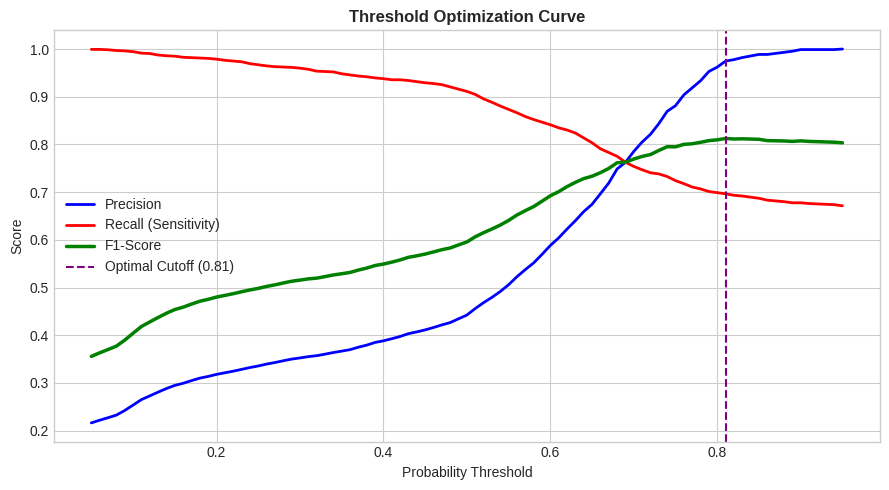

In [21]:
# Model Predictions
prob_dnn = dnn.predict(X_test_scaled, batch_size=256, verbose=0).flatten()

# Threshold Sweep
thresholds = np.linspace(0.05, 0.95, 91)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    pred_t = (prob_dnn >= t).astype(int)
    p = precision_score(y_test, pred_t, zero_division=0)
    r = recall_score(y_test, pred_t, zero_division=0)
    f = f1_score(y_test, pred_t, zero_division=0)
    precisions.append(p)
    recalls.append(r)
    f1s.append(f)

opt_idx = np.argmax(f1s)
optimal_threshold = thresholds[opt_idx]
print(f"Optimal Threshold (maximizing F1): {optimal_threshold:.2f} (F1 = {f1s[opt_idx]:.4f})")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, 'b-', label='Precision', lw=2)
plt.plot(thresholds, recalls, 'r-', label='Recall (Sensitivity)', lw=2)
plt.plot(thresholds, f1s, 'g-', label='F1-Score', lw=2.5)
plt.axvline(optimal_threshold, color='purple', linestyle='--', label=f'Optimal Cutoff ({optimal_threshold:.2f})')
plt.title('Threshold Optimization Curve', fontweight='bold')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
# Comprehensive Model Benchmark Table
def get_metrics_row(name, y_true, prob, thresh=0.5):
    pred = (prob >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Model': name,
        'Threshold': thresh,
        'Accuracy': accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall (Sens)': recall_score(y_true, pred, zero_division=0),
        'Specificity': tn / (tn + fp),
        'F1-Score': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob),
        'PR-AUC': average_precision_score(y_true, prob)
    }

results = [
    get_metrics_row('Logistic Regression (Balanced)', y_test, prob_lr, 0.50),
    get_metrics_row('Random Forest (Balanced)', y_test, prob_rf, 0.50),
    get_metrics_row('Deep Neural Network (Default)', y_test, prob_dnn, 0.50),
    get_metrics_row(f'Deep Neural Network (Opt Thresh)', y_test, prob_dnn, optimal_threshold)
]

df_res = pd.DataFrame(results)
display(df_res.style.format({col: '{:.4f}' for col in df_res.columns if col not in ['Model', 'Threshold']}))


,Model,Threshold,Accuracy,Precision,Recall (Sens),Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression (Balanced),0.500000,0.8854,0.4270,0.8766,0.8862,0.5743,0.9607,0.8126
1,Random Forest (Balanced),0.500000,0.9167,0.5163,0.8829,0.9200,0.6516,0.9758,0.8776
2,Deep Neural Network (Default),0.500000,0.8908,0.4424,0.9112,0.8889,0.5956,0.9745,0.8737
3,Deep Neural Network (Opt Thresh),0.810000,0.9716,0.9747,0.6965,0.9983,0.8125,0.9745,0.8737


## 13. Comparative ROC Curves, PR Curves & Confusion Matrix


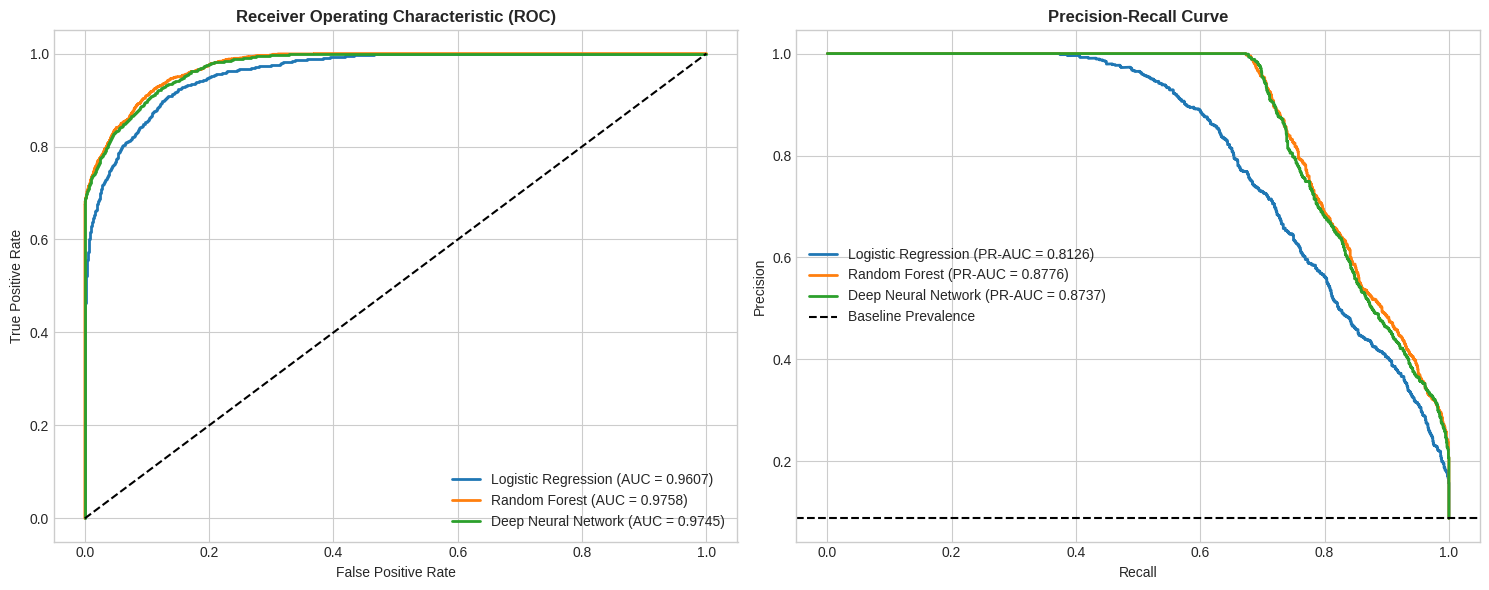

In [23]:
# ROC & PR Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC
for name, p in [('Logistic Regression', prob_lr), ('Random Forest', prob_rf), ('Deep Neural Network', prob_dnn)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    auc_v = roc_auc_score(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_v:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# PR
for name, p in [('Logistic Regression', prob_lr), ('Random Forest', prob_rf), ('Deep Neural Network', prob_dnn)]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    pr_v = average_precision_score(y_test, p)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {pr_v:.4f})")
axes[1].axhline(y=np.mean(y_test), color='k', linestyle='--', label='Baseline Prevalence')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()


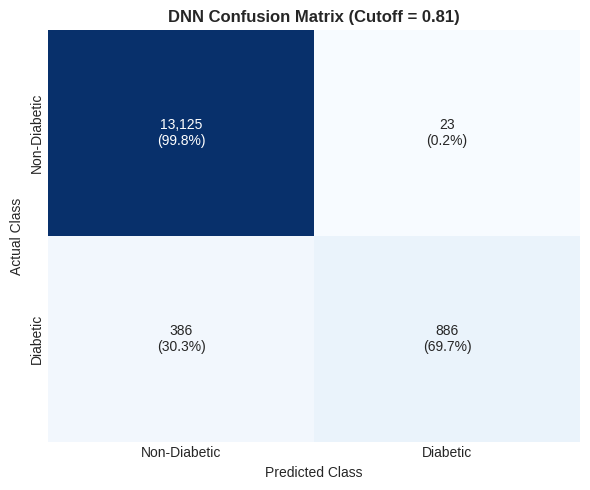

In [24]:
# Confusion Matrix Heatmap for DNN at Optimal Threshold
pred_opt = (prob_dnn >= optimal_threshold).astype(int)
cm = confusion_matrix(y_test, pred_opt)
cm_pct = cm / cm.sum(axis=1)[:, np.newaxis] * 100

annot = np.empty_like(cm, dtype=object)
for i in range(2):
    for j in range(2):
        annot[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)"

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Non-Diabetic', 'Diabetic'],
            yticklabels=['Non-Diabetic', 'Diabetic'])
plt.title(f'DNN Confusion Matrix (Cutoff = {optimal_threshold:.2f})', fontweight='bold')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()


## 14. Explainable AI (XAI) via SHAP
We interpret the Deep Neural Network using **SHapley Additive exPlanations (SHAP)**.
To maintain high computational efficiency without sacrificing attribution fidelity, we draw a representative background cohort of 100 patient vectors from `X_train_scaled`.


PermutationExplainer explainer: 51it [00:14,  1.16it/s]
/tmp/ipykernel_981/193853523.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(np.squeeze(shap_values.values), test_sample, feature_names=feature_names, show=False)


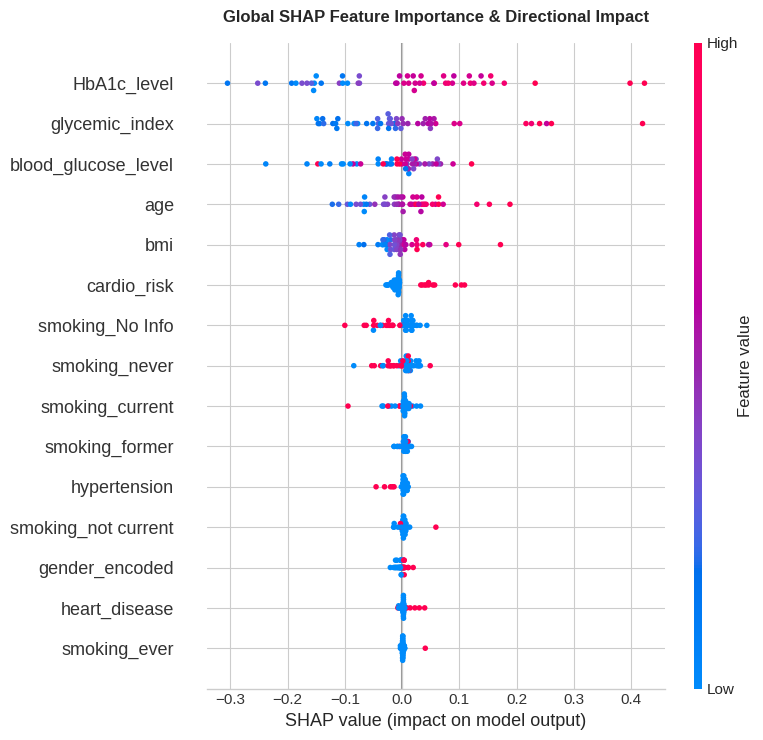

In [25]:
# SHAP Attribution Analysis
bg_indices = np.random.choice(X_train_scaled.shape[0], size=100, replace=False)
background_data = X_train_scaled[bg_indices]

test_indices = np.random.choice(X_test_scaled.shape[0], size=50, replace=False)
test_sample = X_test_scaled[test_indices]

explainer = shap.Explainer(dnn, background_data)
shap_values = explainer(test_sample)

# Global Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(np.squeeze(shap_values.values), test_sample, feature_names=feature_names, show=False)
plt.title('Global SHAP Feature Importance & Directional Impact', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


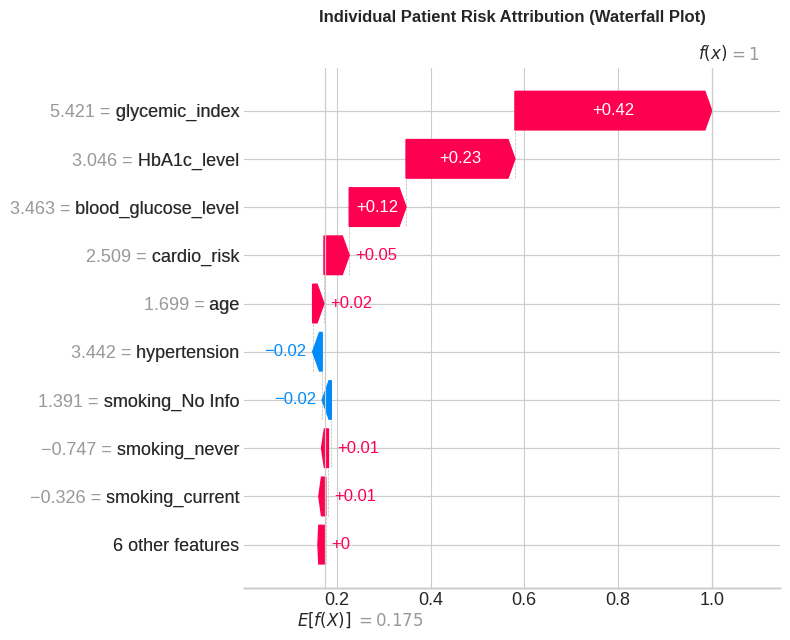

In [26]:
# Local Waterfall Explanation for Individual High-Risk Patient
vals_all = np.squeeze(shap_values.values)
risk_scores = np.sum(vals_all, axis=1)
max_idx = int(np.argmax(risk_scores))

raw_bv = shap_values.base_values[max_idx]
scalar_bv = float(np.squeeze(raw_bv)) if hasattr(raw_bv, '__len__') else float(raw_bv)

single_exp = shap.Explanation(
    values=vals_all[max_idx],
    base_values=scalar_bv,
    data=test_sample[max_idx],
    feature_names=feature_names
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(single_exp, max_display=10, show=False)
plt.title('Individual Patient Risk Attribution (Waterfall Plot)', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 15. Individual Patient Prediction Function
We construct `predict_diabetes(patient_data)` implementing the exact preprocessing, scaling, DNN inference, and clinical risk categorization.


In [27]:
def predict_diabetes(patient_dict, threshold=optimal_threshold):
    """
    Predicts patient diabetes risk given demographic and clinical biomarkers.
    Returns:
    - Diagnostic prediction: Diabetic / Non-Diabetic
    - Probability score (0.0 to 1.0)
    - Risk percentage
    - Risk category: Low (<25%), Moderate (25-50%), High (>50%)
    """
    row = {
        'age': patient_dict['age'],
        'hypertension': patient_dict['hypertension'],
        'heart_disease': patient_dict['heart_disease'],
        'bmi': patient_dict['bmi'],
        'HbA1c_level': patient_dict['HbA1c_level'],
        'blood_glucose_level': patient_dict['blood_glucose_level'],
        'gender_encoded': 1 if patient_dict['gender'] == 'Male' else 0,
        'cardio_risk': patient_dict['hypertension'] + patient_dict['heart_disease'],
        'glycemic_index': (patient_dict['HbA1c_level'] / 5.7) * (patient_dict['blood_glucose_level'] / 100.0)
    }
    for opt in ['No Info', 'current', 'ever', 'former', 'never', 'not current']:
        row[f'smoking_{opt}'] = 1 if patient_dict['smoking_history'] == opt else 0

    df_patient = pd.DataFrame([row]).reindex(columns=feature_names, fill_value=0)
    scaled_vector = scaler.transform(df_patient)

    prob = float(dnn.predict(scaled_vector, verbose=0)[0][0])

    if prob < 0.25:
        risk_category = "Low Risk"
    elif prob < 0.50:
        risk_category = "Moderate Risk"
    else:
        risk_category = "High Risk"

    return {
        'diagnosis': 'Diabetic' if prob >= threshold else 'Non-Diabetic',
        'probability': prob,
        'risk_percentage': f"{prob * 100:.2f}%",
        'risk_category': risk_category
    }

# Test with Clinical Personas
p_healthy = {'gender': 'Female', 'age': 28, 'hypertension': 0, 'heart_disease': 0, 'smoking_history': 'never', 'bmi': 22.0, 'HbA1c_level': 4.9, 'blood_glucose_level': 90}
p_diabetic = {'gender': 'Male', 'age': 65, 'hypertension': 1, 'heart_disease': 1, 'smoking_history': 'former', 'bmi': 34.0, 'HbA1c_level': 8.2, 'blood_glucose_level': 210}

print("Healthy Persona Result: ", predict_diabetes(p_healthy))
print("Diabetic Persona Result:", predict_diabetes(p_diabetic))


Healthy Persona Result:  {'diagnosis': 'Non-Diabetic', 'probability': 2.1111249282057543e-07, 'risk_percentage': '0.00%', 'risk_category': 'Low Risk'}
Diabetic Persona Result: {'diagnosis': 'Diabetic', 'probability': 0.9999995827674866, 'risk_percentage': '100.00%', 'risk_category': 'High Risk'}


## 16. Model & Pipeline Artifact Serialization
All assets required for standalone deployment in Streamlit are serialized.


In [28]:
# Save Artifacts
os.makedirs("../models", exist_ok=True)
dnn.save("../models/diabetes_dnn.keras")
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(background_data, "../models/shap_background.pkl")

meta = {
    'optimal_threshold': float(optimal_threshold),
    'feature_names': feature_names,
    'results': df_res.to_dict(orient='records')
}
joblib.dump(meta, "../models/model_metadata.pkl")
print("All artifacts successfully saved to ../models/.")


All artifacts successfully saved to ../models/.
